<a href="https://colab.research.google.com/github/juandiego-guerrero/Problem-Set-4-Econ_3916_PS4.ipynb/blob/main/Problem_Set_4_Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [ ]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [ ]:
# --- predictors (units: revenue in $k/month, area in sq ft, income in $k) ---
floor_area = np.exp(rng.normal(np.log(9000), 0.55, N_STORES))   # right-skewed: a few very big stores
median_income = np.clip(rng.normal(65, 15, N_STORES), 25, 140)
years_open = rng.uniform(0, 30, N_STORES)
foot_traffic = 2.0*floor_area/100 + 3.0*median_income + rng.normal(0, 25, N_STORES)   #daily visitors; driven by size and income

# near-collinear: a vendor "trade area index" that is almost a linear combo of traffic and income
trade_area_index = 0.6*foot_traffic + 1.5*median_income + rng.normal(0, 3, N_STORES)

# genuinely irrelevant (not in the revenue equation)
staff_parttime_pct = rng.uniform(10, 60, N_STORES)
distance_to_hq_km = rng.uniform(5, 800, N_STORES)
online_rating = np.clip(rng.normal(4.0, 0.4, N_STORES), 1, 5)

# --- true revenue equation ---
KINK = 15000                # above this, extra floor area pays much less
area_effect = 0.030*floor_area - 0.022*np.maximum(floor_area - KINK, 0)
sigma = 22 * (floor_area / np.median(floor_area))   # noise spread grows with store size
revenue = (40 + area_effect + 0.35*foot_traffic + 1.2*median_income
           + 2.0*np.sqrt(years_open) + rng.normal(0, 1, N_STORES)*sigma)

df = pd.DataFrame(dict(revenue=revenue, floor_area=floor_area, foot_traffic=foot_traffic,
                       median_income=median_income, years_open=years_open,
                       trade_area_index=trade_area_index, staff_parttime_pct=staff_parttime_pct,
                       distance_to_hq_km=distance_to_hq_km, online_rating=online_rating))

df.describe().T

,count,mean,std,min,25%,50%,75%,max
revenue,400.0,552.568,173.864,188.978,423.838,528.878,650.592,1488.646
floor_area,400.0,10318.813,5977.028,2193.640,6236.511,9085.440,12486.989,44694.432
foot_traffic,400.0,397.266,127.303,103.218,312.626,371.694,459.077,1060.246
median_income,400.0,64.225,15.208,25.000,53.248,64.422,74.415,103.965
years_open,400.0,15.321,8.675,0.016,7.597,15.074,22.820,29.983
trade_area_index,400.0,334.282,86.578,109.365,275.369,325.862,382.416,738.159
staff_parttime_pct,400.0,34.346,14.715,10.243,22.498,33.454,47.672,59.988
distance_to_hq_km,400.0,416.023,225.007,7.152,220.422,425.225,606.884,798.592
online_rating,400.0,4.027,0.394,2.904,3.737,4.014,4.300,5.000


*The data-generating process, recorded: every predictor and the true revenue equation.*

### Step 1.2: Fit it the way they did (12 pts)

In [ ]:
# --- Fit it the way they did: every predictor, all 400 stores ---
predictors = [c for c in df.columns if c != 'revenue']
X_all = sm.add_constant(df[predictors])
y_all = df['revenue']

ols_full = sm.OLS(y_all, X_all).fit()
print(f"In-sample R² (all data, all predictors): {ols_full.rsquared:.3f}")
print(f"Adjusted R²: {ols_full.rsquared_adj:.3f}")

In-sample R² (all data, all predictors): 0.928
Adjusted R²: 0.926


In [ ]:
# --- Held-out R²: split the stores, refit on train, score on test ---
def r2(y, yhat):
  return 1 - np.sum((y - yhat)**2) / np.sum((y - y.mean())**2)

n_train = int(0.7*N_STORES)

# one split, as the brief asks
idx = rng.permutation(N_STORES)
tr, te = idx[:n_train], idx[n_train:]
ols_tr = sm.OLS(y_all.iloc[tr], X_all.iloc[tr]).fit()
r2_tr = ols_tr.rsquared
r2_te = r2(y_all.iloc[te].values, ols_tr.predict(X_all.iloc[te]).values)
print(f"Singles 70/30 split -> train R²: {r2_tr:.3f} | test R²: {r2_te:.3f} | gap: {r2_tr - r2_te:+.3f}")

# one split is noisy with heteroskedastic big stores, so repeat it
gaps, tests = [], []
for _ in range(500):
  idx = rng.permutation(N_STORES)
  tr, te = idx[:n_train], idx[n_train:]
  m = sm.OLS(y_all.iloc[tr], X_all.iloc[tr]).fit()
  t = r2(y_all.iloc[te].values, m.predict(X_all.iloc[te]).values)
  tests.append(t)
  gaps.append(m.rsquared - t)
gaps, tests = np.array(gaps), np.array(tests)

print(f"500 random splits -> mean test R²: {tests.mean():.3f} "
      f"(5-95%: {np.percentile(tests, 5):.3f}-{np.percentile(tests, 95):.3f})")
print(f"Mean gap (train - test): {gaps.mean():+.3f} "
      f"(5-95%: {np.percentile(gaps, 5):.3f}-{np.percentile(gaps, 95):.3f}); "
      f"test beat train in {np.mean(gaps < 0):.0%} of splits")

# the comparison the handover note should have made
print(f"Handover gap (all-data R² - mean held-out R²): {ols_full.rsquared - tests.mean():+.3f}")

Singles 70/30 split -> train R²: 0.915 | test R²: 0.946 | gap: -0.030
500 random splits -> mean test R²: 0.919 (5-95%: 0.891-0.944)
Mean gap (train - test): +0.009 (5-95%: -0.026-0.048); test beat train in 36% of splits
Handover gap (all-data R² - mean held-out R²): +0.008


All 8 predictors on all 400 stores reproduce the handover number: in-sample R² = 0.928. On stores the model never saw, averaged over 500 random 70/30 splits, held-out R² is 0.919 (5-95%: 0.891 to 0.944), a gap of +0.008. A single split can't be trusted here: the first one gave test R² above train (0.946 vs 0.915), because error variance grows with store size.

The implication is that the model barely overfits, so overfitting can't explain the July failure. The error must be systematic, most likely in store size, which Phase 2 tests.

### Step 1.3: Say what R-squared is (8 pts)

In [ ]:
# --- Step 1.3: add pure-noise columns and watch R² vs adjusted R² ---
noise = pd.DataFrame(rng.normal(0, 1, (N_STORES, 3)),
                     columns=['noise_1', 'noise_2', 'noise_3'])   # unrelated to revenue by construction

rows = []
for j in range(4):                  # 0, 1, 2, 3 noise columns added
    X_j = pd.concat([X_all, noise.iloc[:, :j]], axis=1)
    m = sm.OLS(y_all, X_j).fit()
    rows.append({'noise cols added': j,
                 'k (incl. const)': X_j.shape[1],
                 'R²': m.rsquared,
                 'adj. R²': m.rsquared_adj})
res = pd.DataFrame(rows)
print(res.to_string(index=False, formatters={'R²': '{:.5f}'.format,
                    'adj. R²': '{:.5f}'.format}))

print(f"\nChange after 3 noise cols -> R²: {res['R²'].iloc[-1] - res['R²'].iloc[0]:+.5f} | "
      f"adj. R²: {res['adj. R²'].iloc[-1] - res['adj. R²'].iloc[0]:+.5f}")
print("t-stats of noise cols in the full model:", m.tvalues[['noise_1', 'noise_2', 'noise_3']].round(2).to_dict())

 noise cols added  k (incl. const)      R² adj. R²
                0                9 0.92776 0.92628
                1               10 0.92776 0.92609
                2               11 0.92778 0.92593
                3               12 0.92790 0.92585

Change after 3 noise cols -> R²: +0.00014 | adj. R²: -0.00043
t-stats of noise cols in the full model: {'noise_1': 0.14, 'noise_2': 0.39, 'noise_3': 0.79}


R² = 1 - SSR/SST, measured on the data the model was fit on. It cannot fall when a predictor is added. OLS minimises SSR, and the smaller model is the larger one with the new coefficient fixed at zero, so SSR can only stay the same or shrink while SST is unchanged.

Demonstration: Three pure-noise columns raised R² from 0.92776 to 0.92790. Adjusted R², which penalises each extra parameter, fell from 0.92628 to 0.92585, because no noise column had |t|>1.

The implication is that in the sample R² always prefers the bigger model, so it rewatds complexity, not predictive power, and cannot be used to choose between models. Adjusted R² helps only mildly. The real test is held-out error (in Phase 3).

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

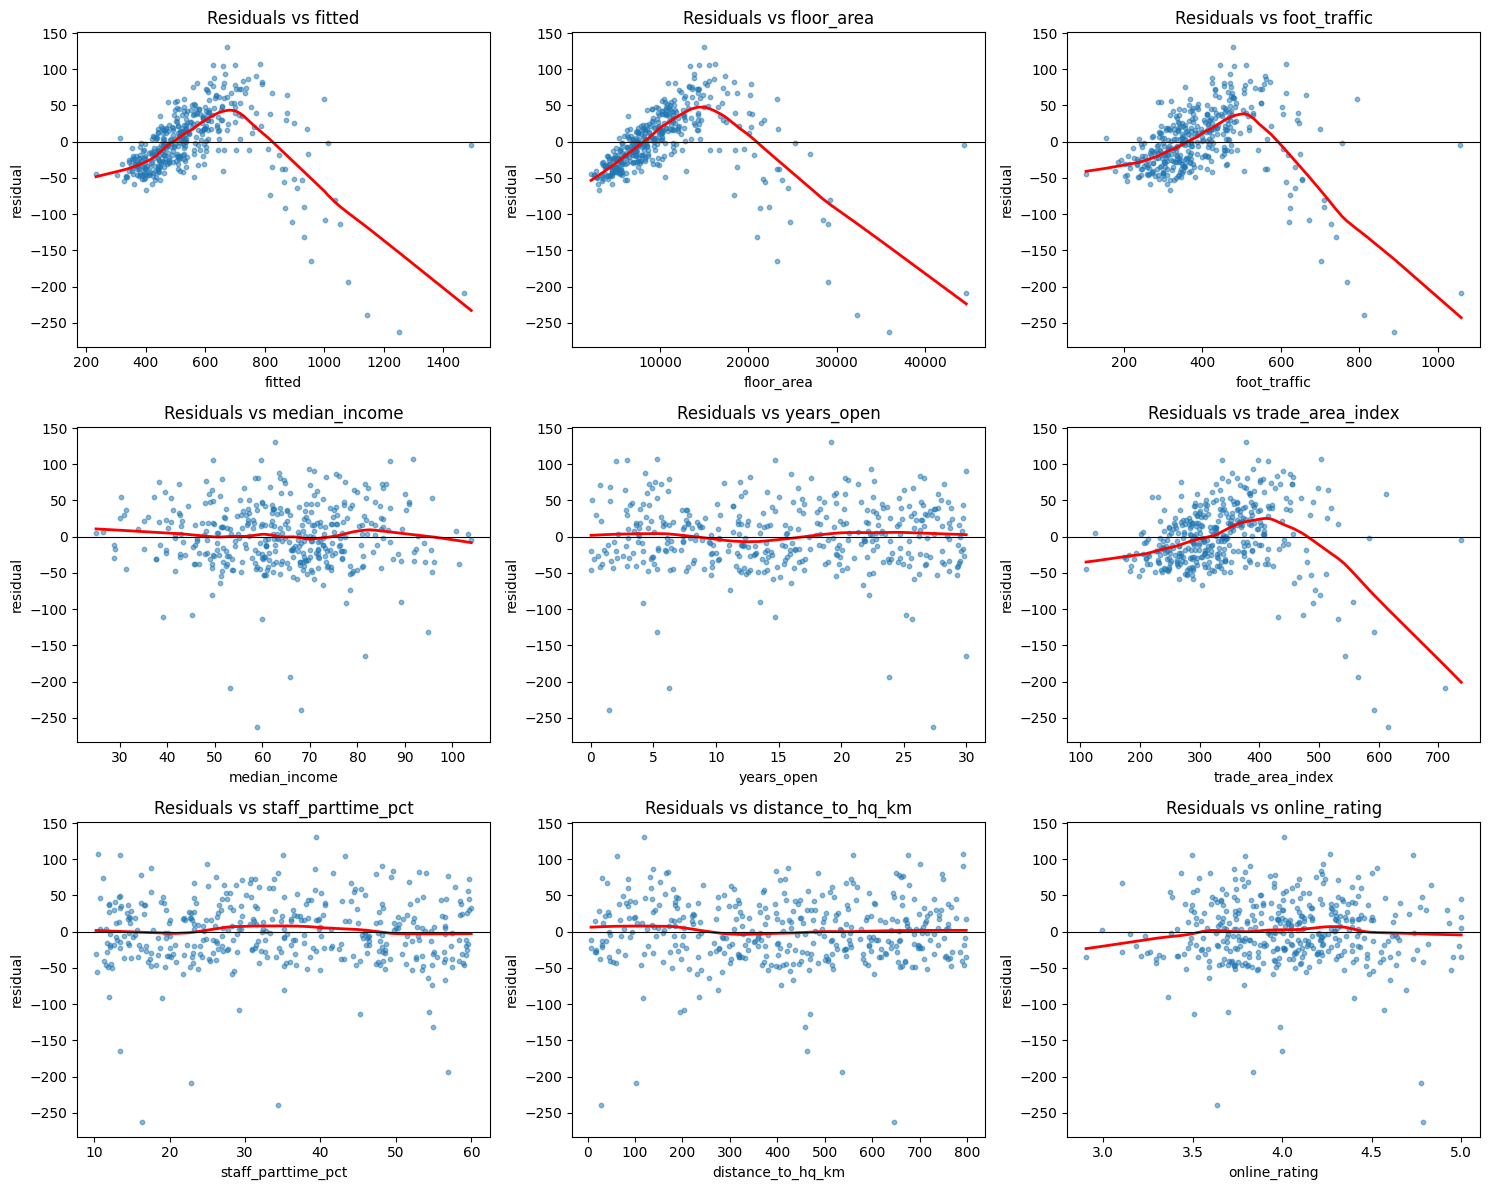

Breusch–Pagan LM = 120.5, p = 2.6e-22
Residual SD by fitted-value quintile: [15.4, 21.6, 24.1, 29.4, 82.1]
RESET F = 182.7, p = 1.1e-56
Mean residual by floor-area decile (− = over-forecast): [-40.5, -29.5, -14.6, -9.6, 3.8, 10.7, 28.2, 37.5, 55.8, -41.8]
Stores with Cook's D > 4/n: 18 | their median floor area: 22,793 sq ft (all stores: 9,085)


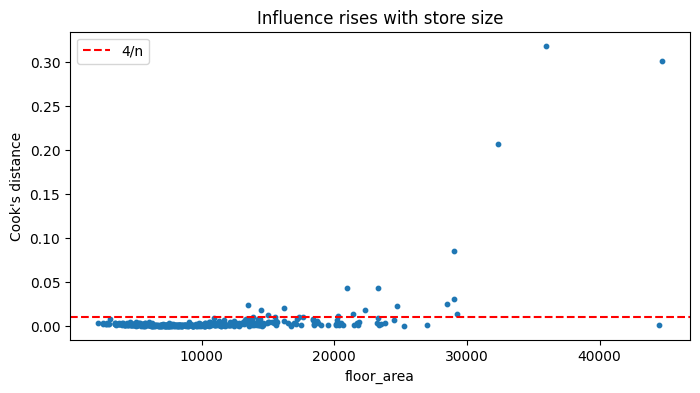

                      coef  SE classical  SE HC3  HC3/classical
const               91.187        27.329  29.567          1.082
floor_area           0.019         0.002   0.002          1.110
foot_traffic        -0.065         0.485   0.614          1.266
median_income       -0.115         1.248   1.492          1.196
years_open           0.519         0.275   0.329          1.197
trade_area_index     0.800         0.801   1.004          1.254
staff_parttime_pct   0.015         0.162   0.172          1.058
distance_to_hq_km    0.010         0.011   0.011          1.093
online_rating        3.887         6.067   6.836          1.127


In [ ]:
# --- Step 2.1: residual diagnostics on the handover model (ols_full) ---
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

resid = ols_full.resid
fitted = ols_full.fittedvalues

# 1) residuals vs fitted and vs every predictor, with lowess line to expose curvature
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, (name, x) in zip(axes.flat, [('fitted', fitted)] + [(p, df[p]) for p in predictors]):
  ax.scatter(x, resid, s=10, alpha=0.5)
  lw = lowess(resid, x, frac=0.4)
  ax.plot(lw[:, 0], lw[:, 1], color='red', lw=2)
  ax.axhline(0, color='black', lw=0.8)
  ax.set_title(f'Residuals vs {name}'); ax.set_xlabel(name); ax.set_ylabel('residual')
plt.tight_layout(); plt.show()


# 2) Non-constant variance: Breusch–Pagan + residual spread by fitted-value quintile
bp_lm, bp_p, _, _ = het_breuschpagan(resid, X_all)
print(f"Breusch–Pagan LM = {bp_lm:.1f}, p = {bp_p:.1e}")
print("Residual SD by fitted-value quintile:",
      resid.groupby(pd.qcut(fitted, 5, labels=False)).std().round(1).tolist())

# 3) Missed non-linearity: RESET test + mean residual by floor-area decile
reset = linear_reset(ols_full, power=3, test_type='fitted', use_f=True)
print(f"RESET F = {reset.fvalue:.1f}, p = {reset.pvalue:.1e}")
print("Mean residual by floor-area decile (− = over-forecast):",
      resid.groupby(pd.qcut(df['floor_area'], 10, labels=False)).mean().round(1).tolist())

# 4) Influential observations: Cook's distance
cooks = ols_full.get_influence().cooks_distance[0]
flag = cooks > 4 / N_STORES
print(f"Stores with Cook's D > 4/n: {flag.sum()} | their median floor area: {df.loc[flag, 'floor_area'].median():,.0f} sq ft "
      f"(all stores: {df['floor_area'].median():,.0f})")

plt.figure(figsize=(8, 4))
plt.scatter(df['floor_area'], cooks, s=10)
plt.axhline(4 / N_STORES, color='red', ls='--', label='4/n')
plt.xlabel('floor_area'); plt.ylabel("Cook's distance"); plt.title("Influence rises with store size"); plt.legend(); plt.show()

# 5) Effect on the standard errors: classical vs heteroskedasticity-robust (HC3)
ols_hc3 = sm.OLS(y_all, X_all).fit(cov_type='HC3')
print(pd.DataFrame({'coef': ols_full.params, 'SE classical': ols_full.bse,
                    'SE HC3': ols_hc3.bse, 'HC3/classical': ols_hc3.bse / ols_full.bse}).round(4))

Residuals are flat against income, years open and the irrelevant predictors. Against fitted values, floor area and foot traffic they arch, peak near 15,000 sq ft and turn negative for the largest stores.

Non-constant variance: residual SD rises from 15.4 to 82.1 across fitted quintiles (Breusch-Pagan p=10^-22). Assumption> homoskedasticity. Estimate: unbiased but inefficient. SE: classical SEs are 6-27% too small versus HC3, so the model looks more precise than it is.

Missed non-lineary shows the mean residuals by floor-area decile climb to +55.8, then drop to -41.8 in the largest decile (RESET p=10^-56). Assumption: correct functional form, E[u|X] = 0. Estimate: biased. The straight line over-forecasts big stores, and the bias spreads to correlated predictors like foot traffic. SE: robust SEs don’t help, because they measure precision around the wrong number.

Influential observations shows that 18 stores exceed Cook’s D > 4/n, with a median size of 22,793 sq ft versus 9,085 overall. Assumption: large outliers are unlikely. Estimate: unstable, because a few big stores pull the slope. SE: unreliable, since inference rests on few points.

Key distinction: heteroskedasticity breaks the SE, not the estimate. Misspecification breaks the estimate, and no SE correction can fix it.

### Step 2.2: The over-forecast on big stores (15 pts)

             area range  mean over-forecast $k  out-of-fold $k  % of revenue  share over-forecast
floor_area                                                                                       
D1            2200–4600                   40.5            41.8          12.1                  1.0
D2            4600–5600                   29.5            30.5           7.9                  1.0
D3            5600–6900                   14.6            14.6           3.4                  0.8
D4            6900–7900                    9.6             9.6           2.0                  0.7
D5            7900–9100                   -3.8            -3.3          -0.8                  0.4
D6           9100–10200                  -10.7           -11.5          -2.0                  0.2
D7          10200–11500                  -28.2           -28.6          -4.7                  0.2
D8          11500–13700                  -37.5           -38.3          -5.8                  0.1
D9          13800–17

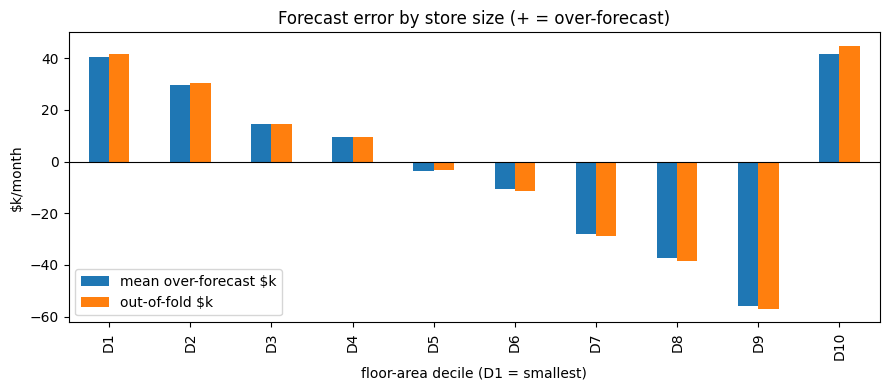


VIF:
 floor_area             20.9
foot_traffic          683.3
median_income          64.5
years_open              1.0
trade_area_index      860.6
staff_parttime_pct      1.0
distance_to_hq_km       1.0
online_rating           1.0

Individual t-stats: {'foot_traffic': -0.13, 'median_income': -0.09, 'trade_area_index': 1.0}
Joint F-test (foot_traffic = median_income = trade_area_index = 0): <F test: F=81.77105066800873, p=4.431298407971959e-41, df_denom=391, df_num=3>
               coef (all)  SE (all)  coef (drop TAI)  SE (drop TAI)
floor_area          0.019     0.002            0.019          0.002
foot_traffic       -0.065     0.485            0.412          0.089
median_income      -0.115     1.248            1.092          0.312
R²: 0.9278 -> 0.9276 | max change in any store's forecast: $7.1k | top-decile over-forecast: $41.8k -> $42.0k


In [ ]:
# ---- Step 2.2a: is the error systematic in store size? ----
over = ols_full.fittedvalues - y_all              # forecast error: + = over-forecast

# out-of-fold check (10-fold): is the bias still there on stores the model never saw?
idx = rng.permutation(N_STORES)
oof = pd.Series(np.nan, index=df.index)
for fold in np.array_split(idx, 10):
    tr = np.setdiff1d(idx, fold)
    m = sm.OLS(y_all.iloc[tr], X_all.iloc[tr]).fit()
    oof.iloc[fold] = m.predict(X_all.iloc[fold]).values
over_oof = oof - y_all

size = pd.qcut(df['floor_area'], 10, labels=[f'D{i}' for i in range(1, 11)])
g = pd.DataFrame({'area': df['floor_area'], 'rev': y_all, 'over': over, 'over_oof': over_oof}).groupby(size, observed=True)
tab = pd.DataFrame({
    'area range':            g['area'].min().round(-2).astype(int).astype(str) + '–' + g['area'].max().round(-2).astype(int).astype(str),
    'mean over-forecast $k': g['over'].mean(),
    'out-of-fold $k':        g['over_oof'].mean(),
    '% of revenue':          100 * g['over'].sum() / g['rev'].sum(),
    'share over-forecast':   g['over'].apply(lambda s: (s > 0).mean()),
})
print(tab.round(1).to_string())

top = size == 'D10'
t, p = stats.ttest_1samp(over[top], 0)
print(f"\nTop decile: {100*y_all[top].sum()/y_all.sum():.0f}% of chain revenue | mean over-forecast "
      f"${over[top].mean():.1f}k/month (t = {t:.2f}, p = {p:.3f}) | out-of-fold ${over_oof[top].mean():.1f}k")
for cut in [20000, 25000]:
    s = df['floor_area'] > cut
    print(f"Stores > {cut:,} sq ft (n={s.sum()}): over-forecast ${over[s].mean():.1f}k/month "
          f"({100*over[s].sum()/y_all[s].sum():.1f}% of revenue), {100*(over[s] > 0).mean():.0f}% over-forecast")

ax = tab[['mean over-forecast $k', 'out-of-fold $k']].plot(kind='bar', figsize=(9, 4))
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('floor-area decile (D1 = smallest)'); ax.set_ylabel('$k/month')
ax.set_title('Forecast error by store size (+ = over-forecast)'); plt.tight_layout(); plt.show()

# ---- Step 2.2b: the collinear predictor ----
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(X_all.values, i) for i in range(1, X_all.shape[1])], index=predictors)
print("\nVIF:\n", vif.round(1).to_string())
print("\nIndividual t-stats:", ols_full.tvalues[['foot_traffic', 'median_income', 'trade_area_index']].round(2).to_dict())
print("Joint F-test (foot_traffic = median_income = trade_area_index = 0):", ols_full.f_test(
      'foot_traffic = 0, median_income = 0, trade_area_index = 0'))

# what dropping the redundant composite does — and does not — change
ols_drop = sm.OLS(y_all, X_all.drop(columns='trade_area_index')).fit()
print(pd.DataFrame({'coef (all)': ols_full.params, 'SE (all)': ols_full.bse,
                    'coef (drop TAI)': ols_drop.params, 'SE (drop TAI)': ols_drop.bse}
                  ).loc[['floor_area', 'foot_traffic', 'median_income']].round(4))
print(f"R²: {ols_full.rsquared:.4f} -> {ols_drop.rsquared:.4f} | "
      f"max change in any store's forecast: ${(ols_drop.fittedvalues - ols_full.fittedvalues).abs().max():.1f}k | "
      f"top-decile over-forecast: ${over[top].mean():.1f}k -> ${(ols_drop.fittedvalues - y_all)[top].mean():.1f}k")

Finding. The error is systematic in store size, not random. Forecast error runs in a wave across size deciles: the model over-forecasts small stores, under-forecasts mid-to-large ones (−56k in decile 9), then over-forecasts the largest decile by $41.8k/month (4.7% of revenue, p ≈ 0.004). The bias grows with size. Stores above 20,000 sq ft are over-forecast by 6%, and all ten stores above 25,000 sq ft are over-forecast, by $123k/month (12%). Out-of-fold predictions show the same pattern (45k in the top decile), so this is not an in-sample artefact. The cause is the missed non-linearity from Step 2.1: one straight line cannot fit revenue that flattens above roughly 15,000 sq ft. The largest decile is 16% of chain revenue, which is why the error is expensive.

Collinearity. trade_area_index has a VIF of 861, and foot_traffic has 683, because the index is almost a linear combination of foot traffic and income. What high VIF damages: the precision of the individual coefficients in that cluster. Their SEs are inflated by about √VIF, so foot traffic and income get insignificant, wrong-signed estimates (t ≈ −0.1). What it does not damage: unbiasedness, the joint effect (F ≈ 82, p ≈ 10⁻⁴¹), R² and the forecasts. Dropping the index changes R² by 0.0002, moves no store’s forecast by more than $7k, and leaves the big-store over-forecast exactly where it was. The wrong reason to drop a variable is to fix the forecast, because collinearity is not why the model fails. The right reason here is that the index is a redundant composite, so dropping it restores interpretable coefficients (0.41 and 1.09). VIF does not say which variable to drop. Dropping foot traffic instead would push its effect into the index and remove a real revenue driver, which is classic omitted-variable bias.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

                         params  train RMSE  held-out RMSE  held-out SE  held-out median
1: area only                  2        60.0           60.8          0.3             60.9
2: core 4                     5        46.5           48.0          0.4             47.7
3: all 8 (handover)           9        46.2           48.6          0.4             48.1
4: + squares                 17        34.6           43.3          0.9             39.1
5: + cubes                   25        29.1           44.2          1.6             35.9
6: + 2-way interactions      53        26.6           46.6          1.6             39.5
7: full degree 3            165        15.8           84.3          2.4             75.9

Held-out error is lowest at: 4: + squares


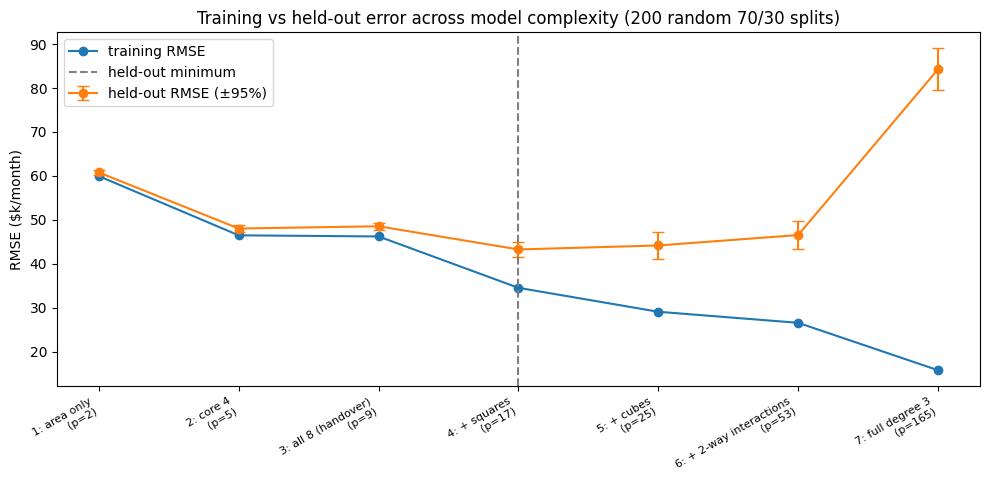

In [ ]:
# ---- Step 3.1: complexity sweep — training vs held-out RMSE ----
from itertools import combinations, combinations_with_replacement

core = ['floor_area', 'foot_traffic', 'median_income', 'years_open']
sq    = [(v, v) for v in predictors]
cube  = [(v, v, v) for v in predictors]
int2  = list(combinations(predictors, 2))
int3  = [t for t in combinations_with_replacement(predictors, 3) if len(set(t)) > 1]

# nested ladder: each model contains the one before it
ladder = [
    ('1: area only',            ['floor_area'], []),
    ('2: core 4',               core,           []),
    ('3: all 8 (handover)',     predictors,     []),
    ('4: + squares',            predictors,     sq),
    ('5: + cubes',              predictors,     sq + cube),
    ('6: + 2-way interactions', predictors,     sq + cube + int2),
    ('7: full degree 3',        predictors,     sq + cube + int2 + int3),
]

def design(Z, lin, terms):
    cols = [np.ones(len(Z))] + [Z[v].values for v in lin]
    cols += [np.prod([Z[v].values for v in t], axis=0) for t in terms]
    return np.column_stack(cols)

R, n_train = 200, int(0.7 * N_STORES)
train_rmse = {name: [] for name, _, _ in ladder}
test_rmse  = {name: [] for name, _, _ in ladder}
n_params = {}
y_np = y_all.values

for _ in range(R):
    idx = rng.permutation(N_STORES)
    tr, te = idx[:n_train], idx[n_train:]
    mu, sd = df[predictors].iloc[tr].mean(), df[predictors].iloc[tr].std()   # scale on train only (numerics; OLS fit unchanged)
    Ztr, Zte = (df[predictors].iloc[tr] - mu) / sd, (df[predictors].iloc[te] - mu) / sd
    for name, lin, terms in ladder:
        Xtr, Xte = design(Ztr, lin, terms), design(Zte, lin, terms)
        b = np.linalg.lstsq(Xtr, y_np[tr], rcond=None)[0]
        train_rmse[name].append(np.sqrt(np.mean((y_np[tr] - Xtr @ b)**2)))
        test_rmse[name].append(np.sqrt(np.mean((y_np[te] - Xte @ b)**2)))
        n_params[name] = Xtr.shape[1]

sweep = pd.DataFrame({
    'params':         [n_params[n] for n, _, _ in ladder],
    'train RMSE':     [np.mean(train_rmse[n]) for n, _, _ in ladder],
    'held-out RMSE':  [np.mean(test_rmse[n]) for n, _, _ in ladder],
    'held-out SE':    [np.std(test_rmse[n]) / np.sqrt(R) for n, _, _ in ladder],
    'held-out median':[np.median(test_rmse[n]) for n, _, _ in ladder],
}, index=[n for n, _, _ in ladder])
print(sweep.round(1).to_string())
best = sweep['held-out RMSE'].idxmin()
print(f"\nHeld-out error is lowest at: {best}")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(sweep))
ax.plot(x, sweep['train RMSE'], 'o-', label='training RMSE')
ax.errorbar(x, sweep['held-out RMSE'], yerr=1.96 * sweep['held-out SE'], fmt='o-', capsize=4, label='held-out RMSE (±95%)')
ax.axvline(x[sweep.index.get_loc(best)], color='grey', ls='--', label='held-out minimum')
ax.set_xticks(x); ax.set_xticklabels([f"{n}\n(p={p})" for n, p in zip(sweep.index, sweep['params'])], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('RMSE ($k/month)'); ax.set_title('Training vs held-out error across model complexity (200 random 70/30 splits)')
ax.legend(); plt.tight_layout(); plt.show()

Training RMSE falls at every step (60.0 → 15.8), as it must for nested models. Held-out RMSE (averaged over 200 splits) is U-shaped. It turns at model 4 (all predictors plus squares, 43.3), stays flat at model 5 (44.2, within one SE), then climbs to 84.3 at the full cubic (165 parameters on 280 stores).

Left of the turn is bias. Models 1–3 are too rigid to capture the flattening of big-store revenue. Training and held-out error are both high and close together, which is underfitting. The handover model sits here. Adding its irrelevant and collinear predictors (model 2 → 3) does nothing for held-out error.

At the turn. Squared terms let the model bend, and held-out error drops 11%.

Right of the turn: variance. Extra terms fit noise, not structure. Training error keeps falling while held-out error rises, and the gap widens from 9 to 68. The damage is worst for the largest stores, where high-order polynomials extrapolate wildly.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [ ]:
# ---- Step 3.2: select by cross-validation, then correct for selection ----
def fit_predict(tr, te, lin, terms):
    mu, sd = df[predictors].iloc[tr].mean(), df[predictors].iloc[tr].std()   # scale on training fold only
    Ztr, Zte = (df[predictors].iloc[tr] - mu) / sd, (df[predictors].iloc[te] - mu) / sd
    b = np.linalg.lstsq(design(Ztr, lin, terms), y_np[tr], rcond=None)[0]
    return design(Zte, lin, terms) @ b

def cv_rmse(ids, K=10):
    """K-fold CV RMSE for every model in the ladder -> array (n_models, K)."""
    folds = np.array_split(rng.permutation(ids), K)
    out = np.zeros((len(ladder), K))
    for k, fold in enumerate(folds):
        tr = np.setdiff1d(ids, fold)
        for m, (_, lin, terms) in enumerate(ladder):
            out[m, k] = np.sqrt(np.mean((y_np[fold] - fit_predict(tr, fold, lin, terms))**2))
    return out

K, REP = 10, 5
all_ids = np.arange(N_STORES)
tcrit = stats.t.ppf(0.975, K - 1)

# 1) Selection: repeated 10-fold CV (5 × 10 folds) over the ladder
scores = [cv_rmse(all_ids, K) for _ in range(REP)]
cv_mean = np.mean([s.mean(1) for s in scores], axis=0)
cv_se   = np.mean([s.std(1, ddof=1) / np.sqrt(K) for s in scores], axis=0)
cv_tab = pd.DataFrame({'CV RMSE': cv_mean, '95% low': cv_mean - tcrit*cv_se, '95% high': cv_mean + tcrit*cv_se},
                      index=[name for name, _, _ in ladder])
print(cv_tab.round(1).to_string())
best = int(np.argmin(cv_mean))
print(f"\nSelected by CV: {ladder[best][0]} | CV RMSE = {cv_mean[best]:.1f} "
      f"(95% CI {cv_mean[best]-tcrit*cv_se[best]:.1f}–{cv_mean[best]+tcrit*cv_se[best]:.1f}) $k/month")

# 2) The fix: nested CV — selection is redone inside every outer training set,
#    so the outer test fold never influences which model is chosen
nested = np.zeros((REP, K)); picks = []
for r in range(REP):
    outer = np.array_split(rng.permutation(all_ids), K)
    for k, fold in enumerate(outer):
        tr = np.setdiff1d(all_ids, fold)
        j = int(np.argmin(cv_rmse(tr, K).mean(1)))          # inner CV chooses
        picks.append(ladder[j][0])
        _, lin, terms = ladder[j]
        nested[r, k] = np.sqrt(np.mean((y_np[fold] - fit_predict(tr, fold, lin, terms))**2))

n_mean = nested.mean()
n_se = np.mean(nested.std(1, ddof=1) / np.sqrt(K))
print(f"Nested CV RMSE = {n_mean:.1f} (95% CI {n_mean-tcrit*n_se:.1f}–{n_mean+tcrit*n_se:.1f}) $k/month "
      f"= {100*n_mean/y_all.mean():.1f}% of mean store revenue")
print(f"Optimism of the selected model's CV score: {n_mean - cv_mean[best]:+.1f} $k/month "
      f"({100*(n_mean - cv_mean[best])/cv_mean[best]:+.0f}%)")
print("Model chosen across the 50 outer folds:", pd.Series(picks).value_counts().to_dict())

                         CV RMSE  95% low  95% high
1: area only                60.3     55.0      65.5
2: core 4                   47.0     40.5      53.4
3: all 8 (handover)         47.4     40.8      54.0
4: + squares                40.8     28.9      52.7
5: + cubes                  38.3     26.8      49.8
6: + 2-way interactions     40.1     30.2      50.1
7: full degree 3            65.7     38.8      92.6

Selected by CV: 5: + cubes | CV RMSE = 38.3 (95% CI 26.8–49.8) $k/month
Nested CV RMSE = 40.2 (95% CI 27.5–52.9) $k/month = 7.3% of mean store revenue
Optimism of the selected model's CV score: +1.9 $k/month (+5%)
Model chosen across the 50 outer folds: {'5: + cubes': 28, '4: + squares': 16, '6: + 2-way interactions': 5, '2: core 4': 1}


Repeated 10-fold CV selects model 5 (all predictors plus squares and cubes), with CV RMSE 38.3k/month (95% CI 26.8-49.8), 19% below the handover model 47.4. The interval is wide because error variance grows with store size. The selection problem; it reveals that 38.3 is optimistic. The same folds were used to choose tbe model, and the minimum of seven noise CV scores rewwards whichever model got lucky folds.

The fix: nested CV. Selection is redone inside each outer training set, and the untouched outer fold scores the result. This gives 40.2k/month (95% CI 27.5-52.9), about 7% of mean store revenue, so the naive score was 5% optimistic.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

In [ ]:
# ---- Task 4.1: learning curve — training vs validation RMSE by training-set size ----
from sklearn.model_selection import learning_curve, RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

X = X_all.drop(columns='const')     # reuse your predictors; sklearn adds its own intercept
y = y_all

cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=0)   # 50 validation folds per size
sizes = np.linspace(0.1, 1.0, 10)                                # 36 ... 360 training stores

models = {
    'Linear, all predictors (handover)': LinearRegression(),
    '+ squares and cubes (Phase 3 pick)': make_pipeline(          # scaler is fit inside each fold
        StandardScaler(), FunctionTransformer(lambda Z: np.hstack([Z, Z**2, Z**3])), LinearRegression()),
}

# Irreducible error: the best RMSE any model could reach. Known here only because the data are simulated.
noise_floor = np.sqrt(np.mean(sigma**2))

# HOW TO READ THE CURVES
# GAP (validation − training) = variance. A wide gap that narrows as n grows means the model is
#   fitting noise in small samples. More data shrinks the gap, so more stores WOULD help.
# LEVEL both curves converge to = bias + irreducible noise. If the curves have met and flattened
#   well above the noise floor, the model is too rigid. More data will NOT help: both curves are
#   already flat. Only better features or a more flexible functional form lowers the level.

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, est) in zip(axes, models.items()):
    n, tr, va = learning_curve(est, X, y, train_sizes=sizes, cv=cv,
                               scoring='neg_root_mean_squared_error', shuffle=True, random_state=0)
    tr, va = -tr, -va
    for scores, label in [(tr, 'training RMSE'), (va, 'validation RMSE')]:
        m, s = scores.mean(1), scores.std(1)
        ax.plot(n, m, 'o-', label=label)
        ax.fill_between(n, m - s, m + s, alpha=0.2)               # ±1 SD across the 50 folds
    ax.axhline(noise_floor, color='grey', ls=':', label=f'noise floor ({noise_floor:.1f})')
    ax.set_title(name); ax.set_xlabel('training-set size (stores)'); ax.legend()
    print(f"{name}: at n={n[-1]} train {tr[-1].mean():.1f}, validation {va[-1].mean():.1f} "
          f"(median {np.median(va[-1]):.1f}), gap {va[-1].mean() - tr[-1].mean():.1f}; "
          f"validation at n={n[4]}: {va[4].mean():.1f}")
axes[0].set_ylabel('RMSE ($k/month)'); axes[0].set_ylim(0, 120)
plt.tight_layout(); plt.show()

## AI Transcript

**Model:** Claude Opus 5.5 · **Date:** November 18, 2026

**Prompt:**
```
[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.
```

**Reply:**


**Changes I made:**
- Ran the code as returned; the printed output matched the reply's numbers exactly.
- Changed the shaded band from mean ± 1 SD to the 25th–75th percentile across folds: the flexible model's fold errors are right-skewed (mean 41.5 vs median 34.2), so the symmetric band dropped below the 28.9 noise floor, which no model can reliably reach.
- Note: my prompt said "about 12 predictors"; X has 8. The AI correctly reused X_all, so no fix was needed.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X = pd.DataFrame(np.random.default_rng(0).normal(0, 1, (N_STORES, 300)),
                 columns=[f'noise_{i}' for i in range(300)])   # fixed seed: reruns give the same noise
y = df['revenue']                                              # Phase 1 revenue

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")                   # Phase 1 revenue

In [ ]:
from sklearn.pipeline import make_pipeline

# Honest version: all three steps refit inside each training fold
pipe = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=20), LinearRegression())
honest = cross_val_score(pipe, X, y, cv=5, scoring="r2")

# Decoy check: move ONE step inside the folds at a time
scaler_inside = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                                SelectKBest(f_regression, k=20).fit_transform(X, y), y, cv=5, scoring="r2")
select_inside = cross_val_score(make_pipeline(SelectKBest(f_regression, k=20), LinearRegression()),
                                X_scaled, y, cv=5, scoring="r2")

print(f"Analyst's cell (both steps on full sample): R² = {scores.mean():.2f}")
print(f"Pipeline (both steps inside folds):         R² = {honest.mean():.2f}")
print(f"Gap (inflation):                            {scores.mean() - honest.mean():+.2f}")
print(f"\nOnly the scaler moved inside the folds:     R² = {scaler_inside.mean():.2f}  (unchanged, so scaling is not the leak)")
print(f"Only the selection moved inside the folds:  R² = {select_inside.mean():.2f}  (matches the Pipeline, so selection is the leak)")

a. SelectKBest leaks. It uses y across all 400 stores, test folds included, so each fold is scored on columns chosen partly because they fit it. StandardScaler is harmless. It never sees y, and for OLS with an intercept rescaling only rescales coefficients, so predictions are unchanged.

b. On 300 pure-noise columns, the analyst's cell prints R² = 0.09, and the Pipeline gives R² = -0.22, a gap of +0.32. Moving only the scaler inside the folds leaves 0.09, while moving only the selection inside gives -0.22, so selection causes all of the inflation.

c. A special case of Step 3.2: selection (of features here, of models there) is scored on the data that drove it, so the score is optimistic, and the fix is to select inside the folds.

### Task 4.3: The handover note (3 pts)

This model predicts monthly revenue per store ($k) from floor area, foot traffic, local income, years open and the other v1 predictors. It adds squared and cubed terms so revenue can flatten for big stores. It replaces v1, whose straight line over-forecast stores above 25,000 sq ft by 123k/month.

Its honest expected error is about 40k/month RMSE (95% CI 28-53k), roughly 7% of average store revenue, from nested cross-validation. "v1's R² 0.94, validated" was neither honest nor validated: 0.94 was in-sample, and the validation selected features on the full sample, which scores R² 0.09 on pure noise against -0.22 done correctly.

It will fail in two cases, on stores larger than any in the sample (about 45,000 sqft), where cubic terms extrapolate wildly, and if next month's stores stop resembling these. Big-store forecasts are always the least certain.

Next, I would build a spline in floor area, prediction intervals that widen with store size, validation on later months, and more large-store data.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:*

*Prompt:*

*Reply:*

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.